<a href="https://colab.research.google.com/github/vjshivani25-hub/DLAC/blob/main/skill3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ultralytics fastapi uvicorn python-multipart requests opencv-python-headless pandas

In [2]:
import os
import sys
import time
import json
import uuid
import threading
import subprocess

import cv2
import torch
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from PIL import Image
from ultralytics import YOLO
from google.colab import files
from IPython.display import display

PROJECT_DIR = "/content/VisionPort_Skill3"

os.makedirs(PROJECT_DIR, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("VISIONPORT - SKILL 3")
print("==============================")
print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())
print("Execution Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

print("Project initialised successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
VISIONPORT - SKILL 3
PyTorch: 2.14.1+cpu
GPU Available: False
Execution Device: cpu
Project initialised successfully!


Saving traffic.jpg to traffic.jpg
API INPUT RECEIVED
File name: traffic.jpg
Image height: 768
Image width: 1280
Image channels: 3
Image size: 182973 bytes


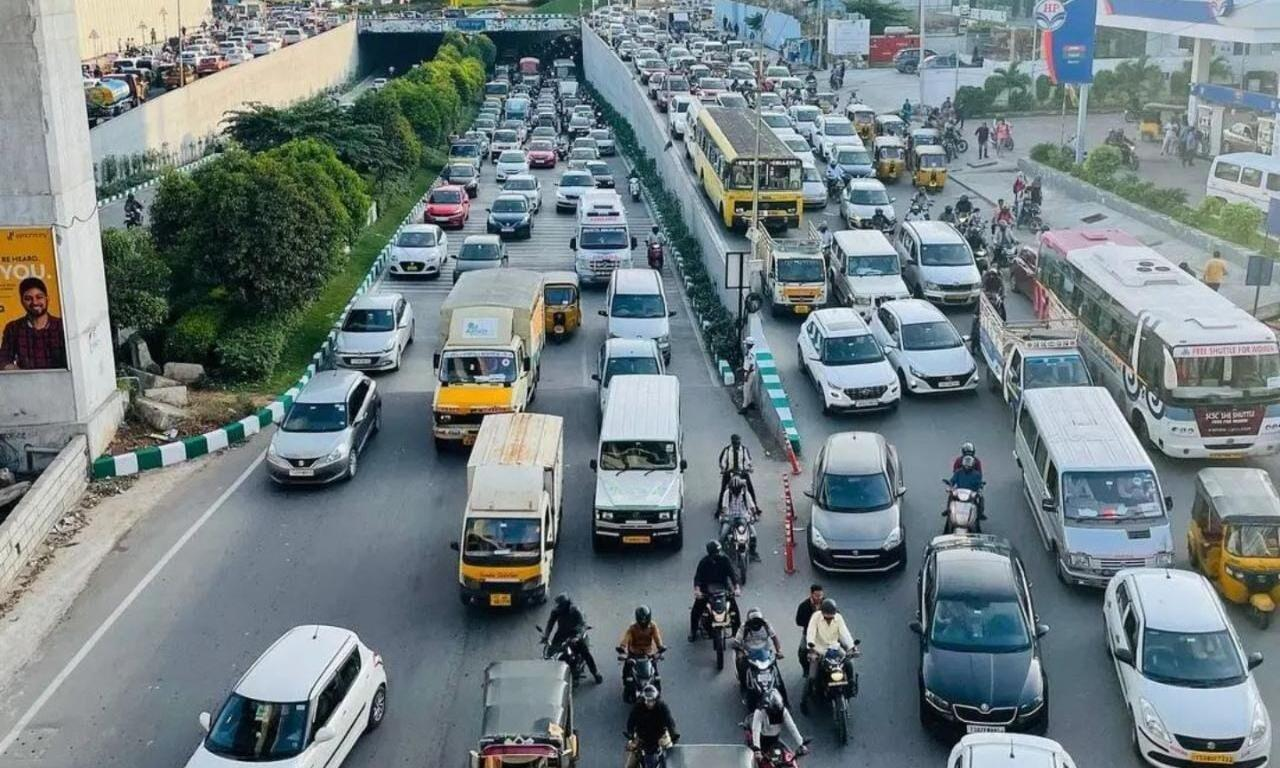

In [3]:
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload a traffic image.")

image_name = next(iter(uploaded))

input_image = os.path.join(
    PROJECT_DIR,
    "traffic_input.jpg"
)

with open(input_image, "wb") as f:
    f.write(uploaded[image_name])

original_image = cv2.imread(input_image)

if original_image is None:
    raise ValueError("Invalid image file.")

print("API INPUT RECEIVED")
print("==============================")
print("File name:", image_name)
print("Image height:", original_image.shape[0])
print("Image width:", original_image.shape[1])
print("Image channels:", original_image.shape[2])
print("Image size:", os.path.getsize(input_image), "bytes")

display(Image.open(input_image))

In [4]:
model = YOLO("yolo11n.pt")

print("YOLO11 MODEL LOADED")
print("==============================")
print("Model:", "YOLO11n")
print("Task:", model.task)
print("Classes:", len(model.names))
print("Device:", DEVICE)

YOLO11 MODEL LOADED
Model: YOLO11n
Task: detect
Classes: 80
Device: cpu


IMAGE PREPROCESSING
Original shape: (768, 1280, 3)
Resized shape: (640, 640, 3)
Normalised shape: (640, 640, 3)
Pixel range: 0.0 to 1.0
Demonstration preprocessing time: 32.263 ms


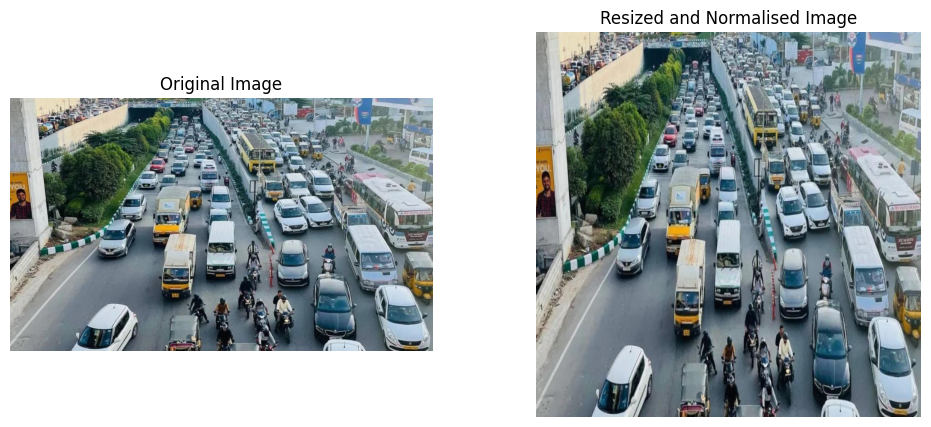

In [5]:
start_preprocessing = time.perf_counter()

image = cv2.imread(input_image)

# Convert BGR to RGB
rgb_image = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

# Resize a copy for visual demonstration
resized_image = cv2.resize(
    rgb_image,
    (640, 640)
)

# Convert pixel values to 0-1 range
normalised_image = resized_image.astype(
    np.float32
) / 255.0

preprocessing_time = (
    time.perf_counter() - start_preprocessing
) * 1000

print("IMAGE PREPROCESSING")
print("==============================")
print("Original shape:", image.shape)
print("Resized shape:", resized_image.shape)
print("Normalised shape:", normalised_image.shape)
print("Pixel range:",
      normalised_image.min(),
      "to",
      normalised_image.max())
print("Demonstration preprocessing time:",
      round(preprocessing_time, 3), "ms")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(normalised_image)
plt.title("Resized and Normalised Image")
plt.axis("off")

plt.show()

In [6]:
print("MODEL EXECUTION STARTED")

start_time = time.perf_counter()

results = model.predict(
    source=input_image,
    imgsz=640,
    conf=0.25,
    device=DEVICE,
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

execution_time = (
    time.perf_counter() - start_time
) * 1000

print("MODEL EXECUTION COMPLETED")
print("==============================")
print("Execution device:", DEVICE)
print("Total elapsed time:",
      round(execution_time, 3), "ms")

print("YOLO internal timing:", results[0].speed)

MODEL EXECUTION STARTED
MODEL EXECUTION COMPLETED
Execution device: cpu
Total elapsed time: 8811.02 ms
YOLO internal timing: {'preprocess': 11.185554000007869, 'inference': 311.8704440000215, 'postprocess': 26.44096200003787}


In [7]:
detections = []

for box in results[0].boxes:

    class_id = int(box.cls[0].item())

    confidence = float(box.conf[0].item())

    coordinates = [
        round(float(value), 2)
        for value in box.xyxy[0].tolist()
    ]

    detections.append({
        "object": model.names[class_id],
        "confidence": round(confidence * 100, 2),
        "bounding_box": coordinates
    })

print("POSTPROCESSING RESULTS")
print("==============================")

print("Total detected objects:", len(detections))

for item in detections:
    print(item)

POSTPROCESSING RESULTS
Total detected objects: 21
{'object': 'car', 'confidence': 83.56, 'bounding_box': [1099.91, 563.03, 1271.5, 767.27]}
{'object': 'car', 'confidence': 82.93, 'bounding_box': [180.95, 621.44, 390.08, 767.56]}
{'object': 'car', 'confidence': 72.55, 'bounding_box': [910.91, 534.76, 1048.58, 730.63]}
{'object': 'car', 'confidence': 67.49, 'bounding_box': [945.74, 731.94, 1079.65, 767.53]}
{'object': 'car', 'confidence': 59.72, 'bounding_box': [803.47, 431.49, 907.77, 576.85]}
{'object': 'car', 'confidence': 58.49, 'bounding_box': [468.69, 658.67, 580.46, 767.3]}
{'object': 'person', 'confidence': 52.16, 'bounding_box': [1.11, 275.29, 66.43, 370.3]}
{'object': 'bus', 'confidence': 50.45, 'bounding_box': [429.09, 268.2, 545.8, 453.14]}
{'object': 'bus', 'confidence': 45.69, 'bounding_box': [686.36, 94.4, 807.48, 238.42]}
{'object': 'car', 'confidence': 44.05, 'bounding_box': [266.45, 368.89, 381.74, 489.0]}
{'object': 'bus', 'confidence': 43.59, 'bounding_box': [1010.39,

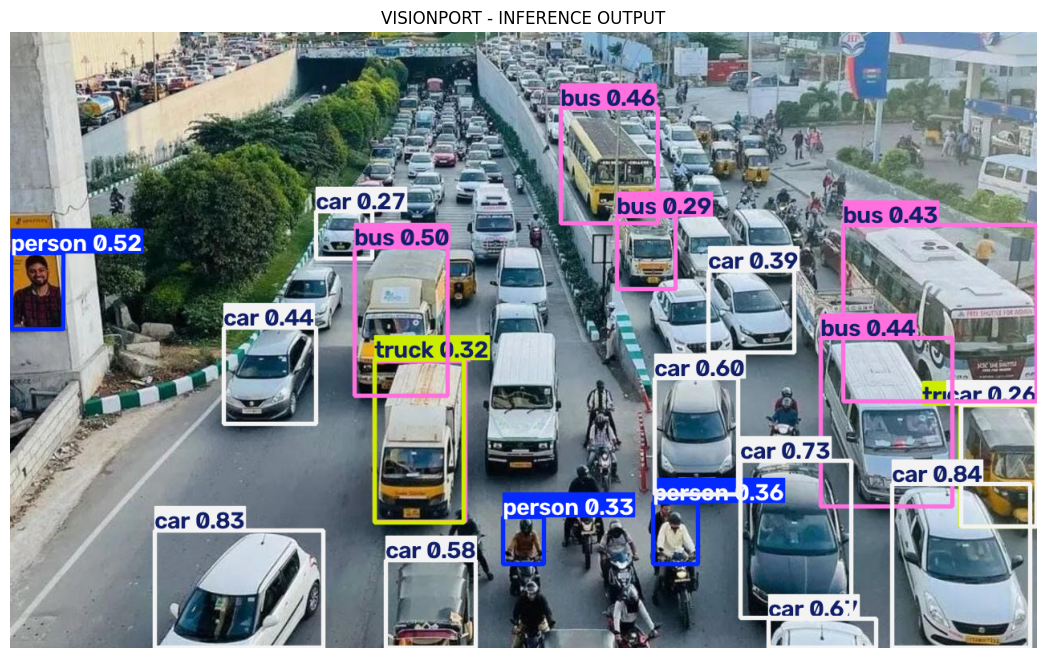

Annotated image generated!


In [8]:
annotated = results[0].plot()

annotated_path = os.path.join(
    PROJECT_DIR,
    "traffic_detected.jpg"
)

cv2.imwrite(annotated_path, annotated)

plt.figure(figsize=(15, 8))

plt.imshow(
    cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
)

plt.title("VISIONPORT - INFERENCE OUTPUT")
plt.axis("off")
plt.show()

print("Annotated image generated!")

In [9]:
%%writefile /content/VisionPort_Skill3/app.py

from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.responses import FileResponse
from ultralytics import YOLO

import cv2
import numpy as np
import os
import time
import uuid
import torch

app = FastAPI(
    title="VisionPort Inference Trace API",
    description="API input, preprocessing, model execution and response",
    version="1.0"
)

BASE_DIR = "/content/VisionPort_Skill3"

MODEL_PATH = os.path.join(BASE_DIR, "yolo11n.pt")

OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")

os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

model = YOLO(MODEL_PATH)


@app.get("/")
def home():

    return {
        "project": "VisionPort",
        "status": "Running",
        "skill": "Inference Request Trace"
    }


@app.post("/infer")
async def inference(file: UploadFile = File(...)):

    request_id = str(uuid.uuid4())

    request_start = time.perf_counter()

    # STAGE 1: API INPUT
    if file.content_type not in [
        "image/jpeg",
        "image/png",
        "image/webp"
    ]:
        raise HTTPException(
            status_code=400,
            detail="Only JPG, PNG and WEBP images are supported."
        )

    image_bytes = await file.read()

    if not image_bytes:
        raise HTTPException(
            status_code=400,
            detail="Uploaded image is empty."
        )

    # STAGE 2: IMAGE PREPROCESSING
    preprocessing_start = time.perf_counter()

    image_array = np.frombuffer(
        image_bytes,
        dtype=np.uint8
    )

    image = cv2.imdecode(
        image_array,
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise HTTPException(
            status_code=400,
            detail="Invalid image."
        )

    height, width = image.shape[:2]

    preprocessing_decode_ms = (
        time.perf_counter() - preprocessing_start
    ) * 1000

    # STAGE 3: MODEL EXECUTION
    inference_start = time.perf_counter()

    results = model.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=DEVICE,
        verbose=False
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inference_elapsed_ms = (
        time.perf_counter() - inference_start
    ) * 1000

    # YOLO internal preprocessing timing
    yolo_timing = results[0].speed

    # STAGE 4: POSTPROCESSING
    postprocessing_start = time.perf_counter()

    detections = []

    if results[0].boxes is not None:

        for box in results[0].boxes:

            class_id = int(box.cls[0].item())

            confidence = float(box.conf[0].item())

            detections.append({
                "object": model.names[class_id],
                "confidence": round(confidence * 100, 2),
                "bounding_box": [
                    round(float(v), 2)
                    for v in box.xyxy[0].tolist()
                ]
            })

    annotated = results[0].plot()

    output_filename = request_id + ".jpg"

    output_path = os.path.join(
        OUTPUT_DIR,
        output_filename
    )

    cv2.imwrite(output_path, annotated)

    postprocessing_ms = (
        time.perf_counter() - postprocessing_start
    ) * 1000

    # STAGE 5: RESPONSE
    total_time_ms = (
        time.perf_counter() - request_start
    ) * 1000

    trace = {
        "request_id": request_id,

        "api_input": {
            "filename": file.filename,
            "content_type": file.content_type,
            "file_size_bytes": len(image_bytes),
            "image_width": width,
            "image_height": height
        },

        "preprocessing": {
            "decode_time_ms": round(
                preprocessing_decode_ms, 3
            ),
            "model_preprocess_time_ms": round(
                yolo_timing["preprocess"], 3
            )
        },

        "model_execution": {
            "model": "YOLO11n",
            "device": str(DEVICE),
            "inference_time_ms": round(
                yolo_timing["inference"], 3
            ),
            "measured_execution_time_ms": round(
                inference_elapsed_ms, 3
            )
        },

        "postprocessing": {
            "time_ms": round(postprocessing_ms, 3),
            "detected_objects": len(detections),
            "detections": detections
        },

        "api_response": {
            "status": "success",
            "status_code": 200,
            "image_url": "/image/" + output_filename
        },

        "total_processing_time_ms": round(
            total_time_ms, 3
        )
    }

    return trace


@app.get("/image/{filename}")
def get_image(filename: str):

    if (
        os.path.basename(filename) != filename
        or not filename.endswith(".jpg")
    ):
        raise HTTPException(
            status_code=400,
            detail="Invalid filename."
        )

    path = os.path.join(OUTPUT_DIR, filename)

    if not os.path.isfile(path):
        raise HTTPException(
            status_code=404,
            detail="Image not found."
        )

    return FileResponse(
        path,
        media_type="image/jpeg"
    )

Writing /content/VisionPort_Skill3/app.py


In [10]:
import shutil

model_source = model.ckpt_path

model_destination = os.path.join(
    PROJECT_DIR,
    "yolo11n.pt"
)

if os.path.abspath(model_source) != os.path.abspath(model_destination):
    shutil.copy2(
        model_source,
        model_destination
    )

print("YOLO model copied successfully!")
print("Location:", model_destination)

YOLO model copied successfully!
Location: /content/VisionPort_Skill3/yolo11n.pt


In [11]:
import subprocess
import requests
import time
import sys
import os

# Stop an existing server from this notebook, if any
if "api_process" in globals():
    if api_process.poll() is None:
        api_process.terminate()
        api_process.wait()

log_path = os.path.join(
    PROJECT_DIR,
    "server.log"
)

log_file = open(log_path, "w")

api_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "app:app",
        "--host",
        "127.0.0.1",
        "--port",
        "8000"
    ],
    cwd=PROJECT_DIR,
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Wait for server readiness
server_ready = False

for i in range(40):

    if api_process.poll() is not None:
        break

    try:
        response = requests.get(
            "http://127.0.0.1:8000/",
            timeout=2
        )

        if response.status_code == 200:
            server_ready = True
            break

    except requests.exceptions.RequestException:
        pass

    time.sleep(1)

if server_ready:

    print("VISIONPORT FASTAPI SERVER STARTED!")
    print(response.json())

else:

    log_file.flush()

    with open(log_path, "r") as f:
        print(f.read())

    raise RuntimeError("FastAPI server failed to start.")

VISIONPORT FASTAPI SERVER STARTED!
{'project': 'VisionPort', 'status': 'Running', 'skill': 'Inference Request Trace'}


In [12]:
request_start = time.perf_counter()

with open(input_image, "rb") as image_file:

    api_response = requests.post(
        "http://127.0.0.1:8000/infer",

        files={
            "file": (
                "traffic_input.jpg",
                image_file,
                "image/jpeg"
            )
        },

        timeout=180
    )

client_elapsed_ms = (
    time.perf_counter() - request_start
) * 1000

api_response.raise_for_status()

trace_result = api_response.json()

print("INFERENCE REQUEST SUCCESSFUL!")
print("HTTP Status:", api_response.status_code)
print("Client elapsed time:", round(client_elapsed_ms, 3), "ms")
print("Request ID:", trace_result["request_id"])

INFERENCE REQUEST SUCCESSFUL!
HTTP Status: 200
Client elapsed time: 1814.775 ms
Request ID: ea97a1bb-987c-4f74-9659-f61401927c8e


In [13]:
print("=" * 55)
print("       VISIONPORT INFERENCE REQUEST TRACE")
print("=" * 55)

print("\n1. API INPUT")
print(json.dumps(
    trace_result["api_input"],
    indent=4
))

print("\n2. PREPROCESSING")
print(json.dumps(
    trace_result["preprocessing"],
    indent=4
))

print("\n3. MODEL EXECUTION")
print(json.dumps(
    trace_result["model_execution"],
    indent=4
))

print("\n4. POSTPROCESSING")
print(json.dumps(
    trace_result["postprocessing"],
    indent=4
))

print("\n5. API RESPONSE")
print(json.dumps(
    trace_result["api_response"],
    indent=4
))

print("\nTOTAL PROCESSING TIME:",
      trace_result["total_processing_time_ms"],
      "ms")

       VISIONPORT INFERENCE REQUEST TRACE

1. API INPUT
{
    "filename": "traffic_input.jpg",
    "content_type": "image/jpeg",
    "file_size_bytes": 182973,
    "image_width": 1280,
    "image_height": 768
}

2. PREPROCESSING
{
    "decode_time_ms": 9.718,
    "model_preprocess_time_ms": 3.892
}

3. MODEL EXECUTION
{
    "model": "YOLO11n",
    "device": "cpu",
    "inference_time_ms": 144.014,
    "measured_execution_time_ms": 1721.607
}

4. POSTPROCESSING
{
    "time_ms": 73.117,
    "detected_objects": 21,
    "detections": [
        {
            "object": "car",
            "confidence": 83.56,
            "bounding_box": [
                1099.91,
                563.03,
                1271.5,
                767.27
            ]
        },
        {
            "object": "car",
            "confidence": 82.93,
            "bounding_box": [
                180.95,
                621.44,
                390.08,
                767.56
            ]
        },
        {
       

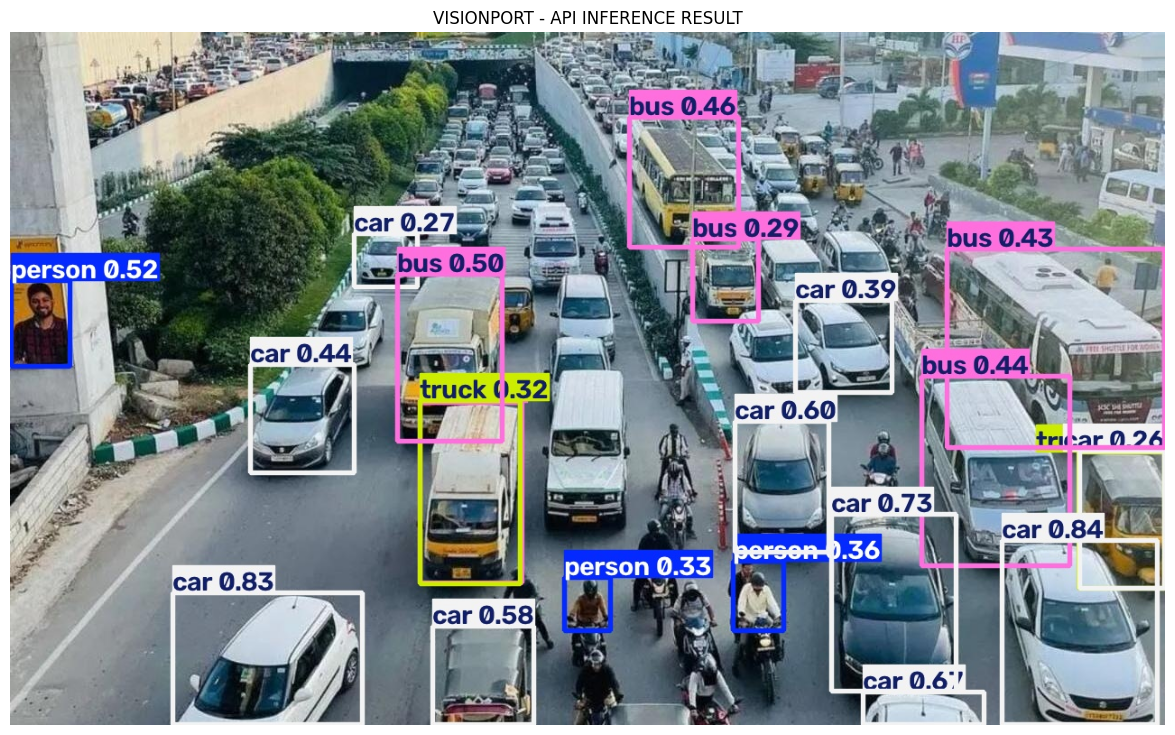

Detected image successfully returned by FastAPI!


In [14]:
image_url = (
    "http://127.0.0.1:8000"
    + trace_result["api_response"]["image_url"]
)

response_image = requests.get(image_url)

response_image.raise_for_status()

detected_image = cv2.imdecode(
    np.frombuffer(
        response_image.content,
        dtype=np.uint8
    ),
    cv2.IMREAD_COLOR
)

plt.figure(figsize=(15, 9))

plt.imshow(
    cv2.cvtColor(
        detected_image,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("VISIONPORT - API INFERENCE RESULT")
plt.axis("off")
plt.show()

print("Detected image successfully returned by FastAPI!")

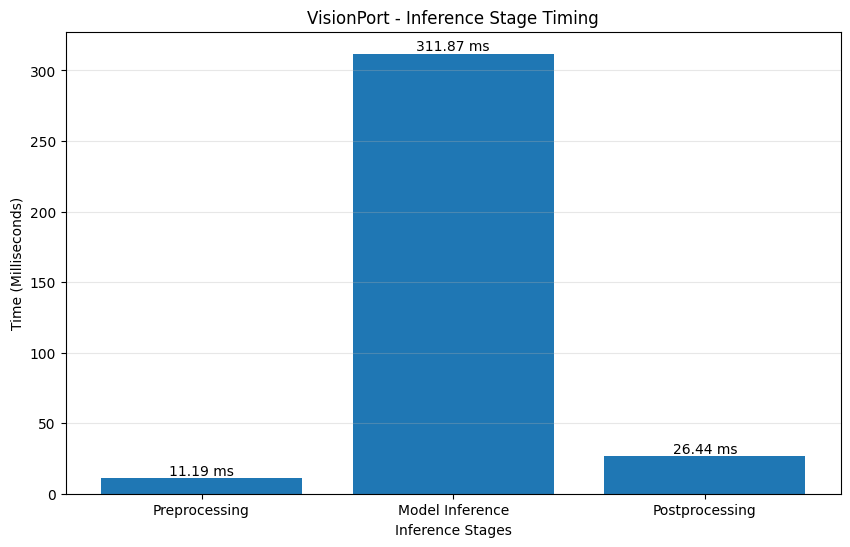

In [15]:
timing = results[0].speed

stage_names = [
    "Preprocessing",
    "Model Inference",
    "Postprocessing"
]

stage_times = [
    timing["preprocess"],
    timing["inference"],
    timing["postprocess"]
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    stage_names,
    stage_times
)

plt.title("VisionPort - Inference Stage Timing")
plt.xlabel("Inference Stages")
plt.ylabel("Time (Milliseconds)")

plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, stage_times):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f} ms",
        ha="center",
        va="bottom"
    )

plt.show()

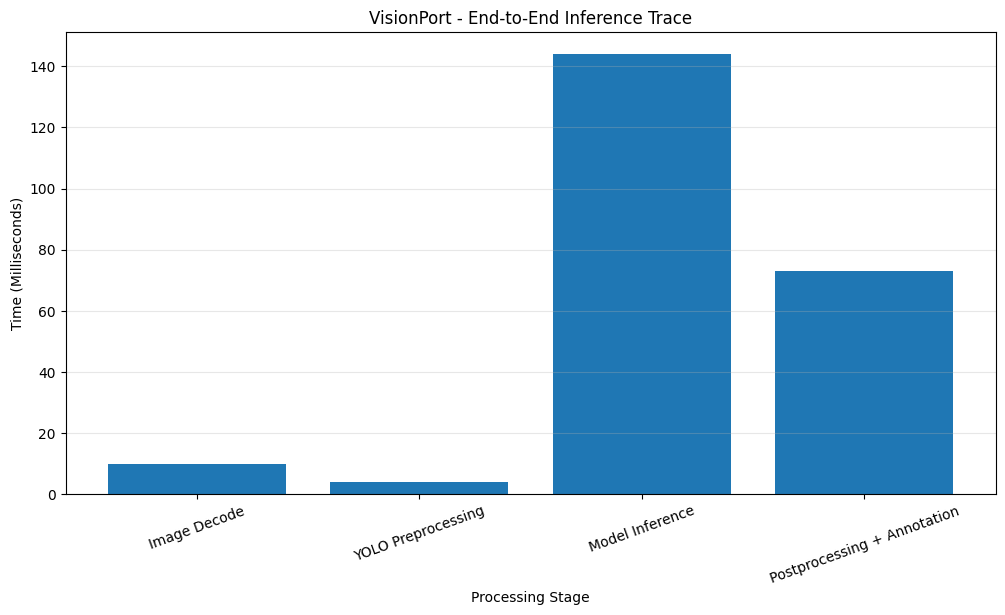

Total server processing time: 1804.53 ms
Client request elapsed time: 1814.775 ms


In [16]:
trace = trace_result

timing_data = {
    "Image Decode": trace["preprocessing"]["decode_time_ms"],
    "YOLO Preprocessing": trace["preprocessing"]["model_preprocess_time_ms"],
    "Model Inference": trace["model_execution"]["inference_time_ms"],
    "Postprocessing + Annotation": trace["postprocessing"]["time_ms"]
}

plt.figure(figsize=(12, 6))

plt.bar(
    timing_data.keys(),
    timing_data.values()
)

plt.title("VisionPort - End-to-End Inference Trace")
plt.xlabel("Processing Stage")
plt.ylabel("Time (Milliseconds)")

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.show()

print("Total server processing time:",
      trace["total_processing_time_ms"], "ms")

print("Client request elapsed time:",
      round(client_elapsed_ms, 3), "ms")

In [17]:
trace_file = os.path.join(
    PROJECT_DIR,
    "inference_trace_report.json"
)

with open(trace_file, "w") as f:

    json.dump(
        trace_result,
        f,
        indent=4
    )

print("Inference trace report saved!")
print(trace_file)

Inference trace report saved!
/content/VisionPort_Skill3/inference_trace_report.json


In [18]:
graph_path = os.path.join(
    PROJECT_DIR,
    "inference_timing_graph.png"
)

plt.figure(figsize=(10, 6))

plt.bar(
    timing_data.keys(),
    timing_data.values()
)

plt.title("VisionPort Inference Request Trace")
plt.ylabel("Milliseconds")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    graph_path,
    bbox_inches="tight"
)

plt.close()

print("Saved:")
print("1. inference_trace_report.json")
print("2. inference_timing_graph.png")
print("3. traffic_detected.jpg")

Saved:
1. inference_trace_report.json
2. inference_timing_graph.png
3. traffic_detected.jpg


In [19]:
zip_path = shutil.make_archive(
    "/content/VisionPort_Skill3_Final",
    "zip",
    PROJECT_DIR
)

print("SKILL 3 COMPLETED!")
print("Project ZIP:", zip_path)

files.download(zip_path)

SKILL 3 COMPLETED!
Project ZIP: /content/VisionPort_Skill3_Final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>